# Predictive Maintenance Failure Prediction for Industrial Equipment Using Machine Learning

**Course:** AAI201 Machine Learning  
**Author:** Drew Menning  
**Date:** May 2026  
**Dataset:** AI4I 2020 Predictive Maintenance Dataset (UCI ML Repository, n=10,000, ~3.4% failure rate)

Build a supervised classifier that predicts machine failure from operating conditions and wear-related variables. Compare a Logistic Regression and Decision Tree baseline against Random Forest and HistGradientBoosting ensembles. Address class imbalance with `class_weight='balanced'` plus probability-threshold tuning, prevent overfitting via stratified splitting, regularization, depth limits, cross-validation, and early stopping, and check fairness across product quality types.

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, precision_recall_curve, roc_curve)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)
print('Setup complete.')

Setup complete.


## 2. Load data

The notebook fetches the AI4I 2020 dataset from the UCI ML Repository. If `ucimlrepo` is not installed it falls back to the direct CSV URL.

In [2]:
def load_ai4i():
    try:
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=601)
        df = pd.concat([ds.data.features, ds.data.targets], axis=1)
    except Exception as e:
        print(f'ucimlrepo unavailable ({e}); falling back to direct CSV.')
        url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00601/ai4i2020.csv'
        df = pd.read_csv(url)
    rename_map = {
        'Air temperature': 'Air temperature [K]',
        'Process temperature': 'Process temperature [K]',
        'Rotational speed': 'Rotational speed [rpm]',
        'Torque': 'Torque [Nm]',
        'Tool wear': 'Tool wear [min]',
    }
    df = df.rename(columns=rename_map)
    return df

df = load_ai4i()
print('Shape:', df.shape)
df.head()

Shape: (10000, 12)


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 3. Exploratory data analysis

In [3]:
print('Columns:', list(df.columns))
print('\nDtypes:')
print(df.dtypes)
print('\nMissing values per column:')
print(df.isna().sum())
print('\nNumeric summary:')
df.describe()

Columns: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Dtypes:
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

Missing values per column:
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


Class distribution for 'Machine failure':
Machine failure
0    9661
1     339
Name: count, dtype: int64
Failure rate: 3.39%


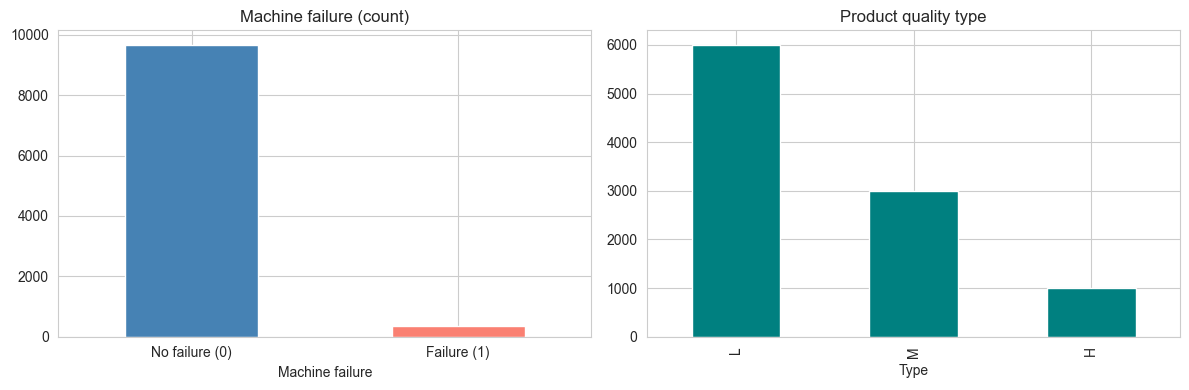

In [4]:
target_col = 'Machine failure'
print(f"Class distribution for '{target_col}':")
print(df[target_col].value_counts())
print(f'Failure rate: {df[target_col].mean()*100:.2f}%')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df[target_col].value_counts().plot(kind='bar', ax=ax[0], color=['steelblue', 'salmon'])
ax[0].set_title('Machine failure (count)')
ax[0].set_xticklabels(['No failure (0)', 'Failure (1)'], rotation=0)
df['Type'].value_counts().plot(kind='bar', ax=ax[1], color='teal')
ax[1].set_title('Product quality type')
plt.tight_layout()
plt.show()

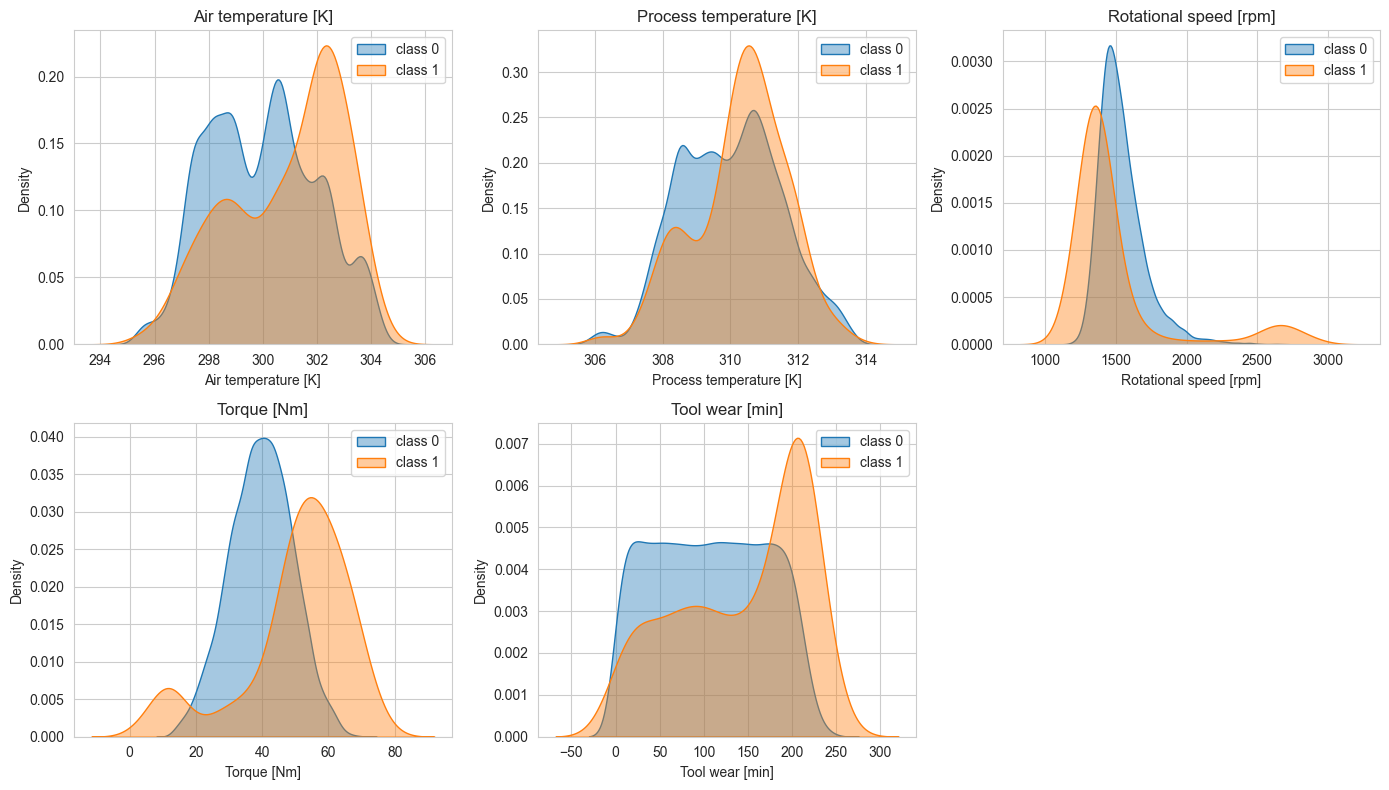

In [5]:
numeric_features = ['Air temperature [K]', 'Process temperature [K]',
                    'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flatten(), numeric_features):
    for cls in [0, 1]:
        sns.kdeplot(df[df[target_col] == cls][col], ax=ax, label=f'class {cls}', fill=True, alpha=0.4)
    ax.set_title(col)
    ax.legend()
axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.show()

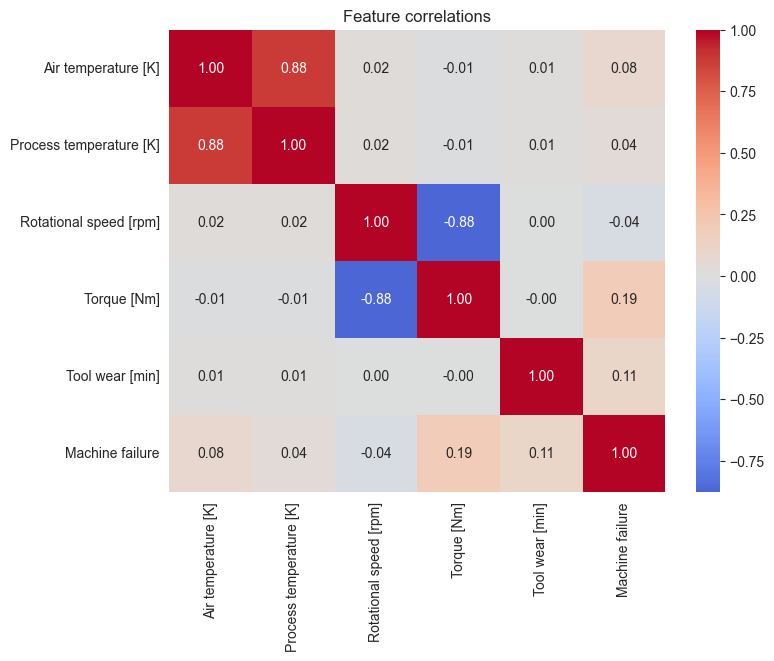

In [6]:
plt.figure(figsize=(8, 6))
corr = df[numeric_features + [target_col]].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Feature correlations')
plt.show()

## 4. Preprocessing

Drop ID columns and the per-failure-mode targets (TWF, HDF, PWF, OSF, RNF) since they leak the binary target. One-hot encode `Type`. Stratified split into 70% train / 15% validation / 15% test.

In [7]:
leaky_cols = ['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
X = df.drop(columns=leaky_cols + [target_col], errors='ignore')
y = df[target_col].astype(int)
X = pd.get_dummies(X, columns=['Type'], drop_first=False)
print('Feature matrix shape:', X.shape)

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.1765, stratify=y_temp, random_state=RANDOM_STATE)

print(f'Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}')
print(f'Train failure rate: {y_train.mean()*100:.2f}%')
print(f'Val failure rate:   {y_val.mean()*100:.2f}%')
print(f'Test failure rate:  {y_test.mean()*100:.2f}%')

Feature matrix shape: (10000, 8)
Train: (6999, 8), Val: (1501, 8), Test: (1500, 8)
Train failure rate: 3.39%
Val failure rate:   3.40%
Test failure rate:  3.40%


## 5. Baseline models

Logistic Regression and Decision Tree set the floor. Both use `class_weight='balanced'` to address the ~3.4% positive class. Logistic Regression uses L2 regularization (`C=1.0`); the Decision Tree uses `max_depth=6` and `min_samples_leaf=20` to prevent overfitting.

In [8]:
def evaluate(model, X_eval, y_eval, name='', threshold=0.5):
    proba = model.predict_proba(X_eval)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        'model': name,
        'accuracy': accuracy_score(y_eval, pred),
        'precision': precision_score(y_eval, pred, zero_division=0),
        'recall': recall_score(y_eval, pred),
        'f1': f1_score(y_eval, pred),
        'roc_auc': roc_auc_score(y_eval, proba),
        'pr_auc': average_precision_score(y_eval, proba)
    }

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

logreg = LogisticRegression(C=1.0, class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE)
logreg.fit(X_train_s, y_train)

dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, class_weight='balanced', random_state=RANDOM_STATE)
dt.fit(X_train, y_train)

results = []
results.append(evaluate(logreg, X_val_s, y_val, 'Logistic Regression'))
results.append(evaluate(dt, X_val, y_val, 'Decision Tree'))
pd.DataFrame(results).round(3)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,0.803,0.111,0.686,0.191,0.840,0.308
1,Decision Tree,0.919,0.273,0.824,0.410,0.911,0.590


## 6. Ensemble models

Random Forest aggregates many decorrelated trees. HistGradientBoostingClassifier is a sklearn-native gradient booster that supports validation-based early stopping (`early_stopping=True`, `n_iter_no_change=20`), which addresses the proposal feedback about avoiding leakage from a held-out validation set.

In [9]:
rf = RandomForestClassifier(
    n_estimators=300, max_depth=12, min_samples_leaf=5,
    class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)

hgb = HistGradientBoostingClassifier(
    max_iter=500, learning_rate=0.05, max_depth=6,
    early_stopping=True, validation_fraction=0.15,
    n_iter_no_change=20, random_state=RANDOM_STATE)
hgb.fit(X_train, y_train)
print(f'HistGradientBoosting stopped at iteration: {hgb.n_iter_}')

results.append(evaluate(rf, X_val, y_val, 'Random Forest'))
results.append(evaluate(hgb, X_val, y_val, 'HistGradientBoosting'))
pd.DataFrame(results).round(3)

HistGradientBoosting stopped at iteration: 118


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,0.803,0.111,0.686,0.191,0.840,0.308
1,Decision Tree,0.919,0.273,0.824,0.410,0.911,0.590
2,Random Forest,0.975,0.614,0.686,0.648,0.944,0.672
3,HistGradientBoosting,0.983,0.882,0.588,0.706,0.951,0.765


## 7. Cross-validation

5-fold stratified CV on the training set confirms that the ranking is stable and not an artifact of the single train/val split. PR-AUC is the headline metric since the classes are imbalanced; it ignores true negatives, which dominate ROC-AUC on a 3.4% positive class.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_models = {
    'Logistic Regression': Pipeline([
        ('s', StandardScaler()),
        ('m', LogisticRegression(C=1.0, class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE))
    ]),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=5, class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE),
    'HistGradientBoosting': HistGradientBoostingClassifier(max_iter=500, learning_rate=0.05, max_depth=6, early_stopping=True, validation_fraction=0.15, n_iter_no_change=20, random_state=RANDOM_STATE)
}
cv_rows = []
for name, m in cv_models.items():
    scores = cross_val_score(m, X_train, y_train, cv=cv, scoring='average_precision', n_jobs=-1)
    cv_rows.append({'model': name, 'pr_auc_mean': scores.mean(), 'pr_auc_std': scores.std()})
cv_df = pd.DataFrame(cv_rows).round(3)
cv_df

,model,pr_auc_mean,pr_auc_std
0,Logistic Regression,0.463,0.053
1,Decision Tree,0.594,0.019
2,Random Forest,0.675,0.064
3,HistGradientBoosting,0.759,0.026


## 8. Threshold selection

On imbalanced data the default 0.5 cutoff is not automatically the right one, so I select the threshold that maximizes F1 on the validation set, then sanity-check it against the precision-recall curve. The chosen threshold is then applied unchanged to the held-out test set in the final evaluation. In a real maintenance setting the cost of a false negative (missed failure) is higher than the cost of a false positive (unnecessary inspection), so a recall-weighted threshold is also reasonable; F1 is used here as a balanced default that doesn't require a cost ratio.

Best threshold (F1-max on val): 0.496
At that threshold: precision=0.886, recall=0.608, F1=0.721


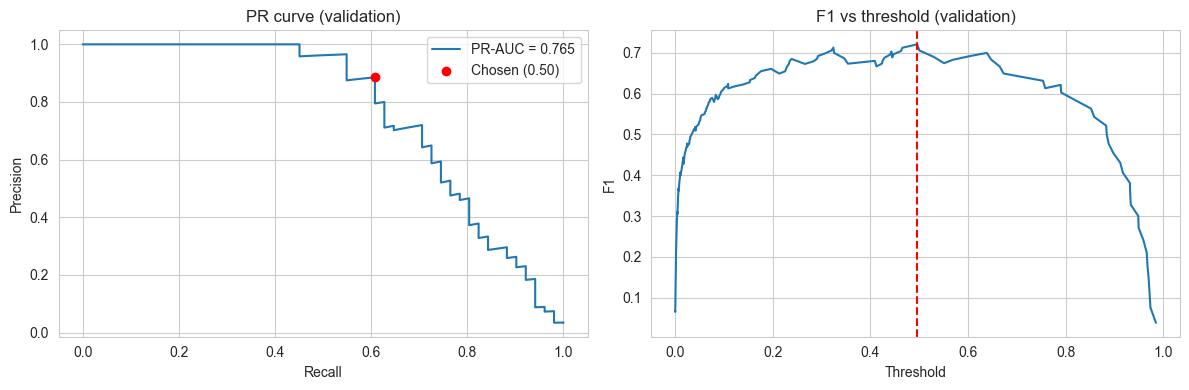

In [11]:
best_model = hgb
val_proba = best_model.predict_proba(X_val)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, val_proba)
f1_scores = 2 * prec * rec / (prec + rec + 1e-9)
best_idx = int(np.argmax(f1_scores[:-1]))
best_threshold = float(thr[best_idx])
print(f'Best threshold (F1-max on val): {best_threshold:.3f}')
print(f'At that threshold: precision={prec[best_idx]:.3f}, recall={rec[best_idx]:.3f}, F1={f1_scores[best_idx]:.3f}')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(rec, prec, label=f'PR-AUC = {average_precision_score(y_val, val_proba):.3f}')
ax[0].scatter(rec[best_idx], prec[best_idx], color='red', zorder=5, label=f'Chosen ({best_threshold:.2f})')
ax[0].set_xlabel('Recall'); ax[0].set_ylabel('Precision')
ax[0].set_title('PR curve (validation)')
ax[0].legend()
ax[1].plot(thr, f1_scores[:-1])
ax[1].axvline(best_threshold, color='red', linestyle='--')
ax[1].set_xlabel('Threshold'); ax[1].set_ylabel('F1')
ax[1].set_title('F1 vs threshold (validation)')
plt.tight_layout()
plt.show()

## 9. Bias and fairness check

The dataset's `Type` column (L, M, H product quality) is the natural fairness axis. I check whether recall and precision are balanced across types, so the model isn't systematically missing failures on one quality grade. Class imbalance was already addressed via `class_weight='balanced'` and threshold tuning above; this cell verifies that the resulting decision rule is consistent across subgroups.

In [12]:
type_cols = [c for c in X.columns if c.startswith('Type_')]
def get_type(row):
    for c in type_cols:
        if row[c] == 1:
            return c.replace('Type_', '')
    return 'Unknown'

val_types = X_val.apply(get_type, axis=1)
val_pred = (val_proba >= best_threshold).astype(int)
fairness_rows = []
for t in ['L', 'M', 'H']:
    mask = val_types == t
    if mask.sum() == 0:
        continue
    fairness_rows.append({
        'type': t,
        'n': int(mask.sum()),
        'failure_rate': y_val[mask].mean(),
        'recall': recall_score(y_val[mask], val_pred[mask], zero_division=0),
        'precision': precision_score(y_val[mask], val_pred[mask], zero_division=0)
    })
pd.DataFrame(fairness_rows).round(3)

,type,n,failure_rate,recall,precision
0,L,924,0.040,0.649,0.96
1,M,459,0.022,0.700,0.70
2,H,118,0.034,0.000,0.00


## 10. Final test-set evaluation

Apply the tuned threshold from validation to the held-out test set. This is the only test-set evaluation; no further tuning happens after this point.

Test-set metrics (HistGradientBoosting + tuned threshold):
  Accuracy:  0.991
  Precision: 0.911
  Recall:    0.804
  F1:        0.854
  ROC-AUC:   0.981
  PR-AUC:    0.882


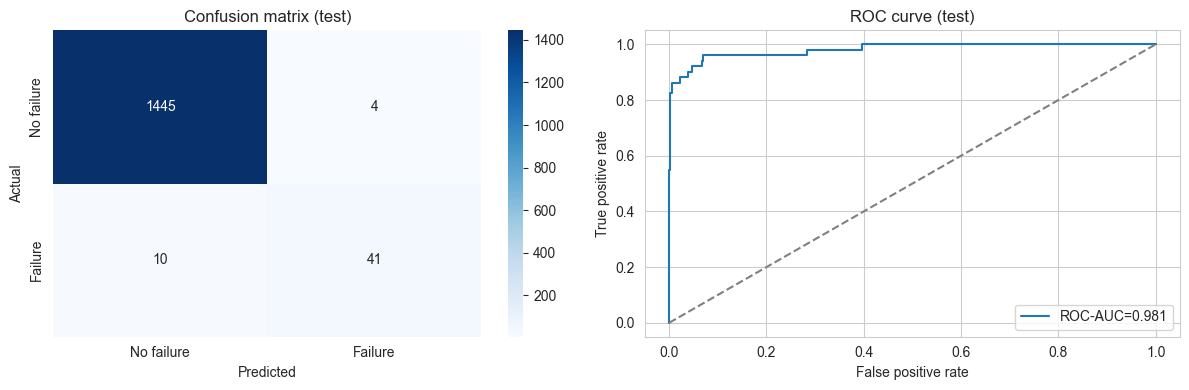


Classification report:
              precision    recall  f1-score   support

  No failure       0.99      1.00      1.00      1449
     Failure       0.91      0.80      0.85        51

    accuracy                           0.99      1500
   macro avg       0.95      0.90      0.92      1500
weighted avg       0.99      0.99      0.99      1500



In [13]:
test_proba = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= best_threshold).astype(int)

print('Test-set metrics (HistGradientBoosting + tuned threshold):')
print(f'  Accuracy:  {accuracy_score(y_test, test_pred):.3f}')
print(f'  Precision: {precision_score(y_test, test_pred, zero_division=0):.3f}')
print(f'  Recall:    {recall_score(y_test, test_pred):.3f}')
print(f'  F1:        {f1_score(y_test, test_pred):.3f}')
print(f'  ROC-AUC:   {roc_auc_score(y_test, test_proba):.3f}')
print(f'  PR-AUC:    {average_precision_score(y_test, test_proba):.3f}')

cm = confusion_matrix(y_test, test_pred)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No failure', 'Failure'],
            yticklabels=['No failure', 'Failure'], ax=ax[0])
ax[0].set_title('Confusion matrix (test)')
ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('Actual')
fpr, tpr, _ = roc_curve(y_test, test_proba)
ax[1].plot(fpr, tpr, label=f'ROC-AUC={roc_auc_score(y_test, test_proba):.3f}')
ax[1].plot([0, 1], [0, 1], '--', color='gray')
ax[1].set_xlabel('False positive rate'); ax[1].set_ylabel('True positive rate')
ax[1].set_title('ROC curve (test)')
ax[1].legend()
plt.tight_layout()
plt.show()

print('\nClassification report:')
print(classification_report(y_test, test_pred, target_names=['No failure', 'Failure']))

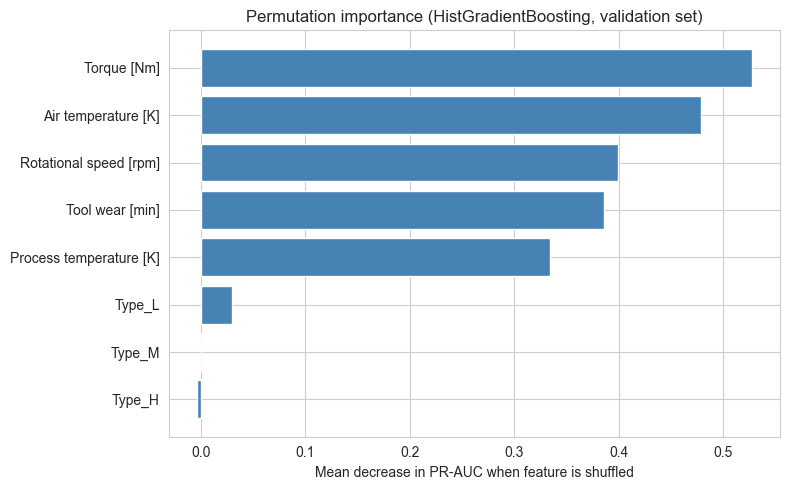

In [14]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(best_model, X_val, y_val, n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1, scoring='average_precision')
imp_df = pd.DataFrame({'feature': X_train.columns, 'importance': perm.importances_mean}).sort_values('importance')
plt.figure(figsize=(8, 5))
plt.barh(imp_df['feature'], imp_df['importance'], color='steelblue')
plt.title('Permutation importance (HistGradientBoosting, validation set)')
plt.xlabel('Mean decrease in PR-AUC when feature is shuffled')
plt.tight_layout()
plt.show()

## 11. Reflection

**Key decisions.** Drop the per-failure-mode columns (TWF, HDF, PWF, OSF, RNF) before training because they're constructed to imply the binary target and would leak. Use `class_weight='balanced'` plus probability-threshold tuning on the validation set rather than synthetic oversampling such as SMOTE; the AI4I dataset is already synthetic, and synthesizing minority samples on top of synthetic data felt like compounding the same modeling assumptions twice. PR-AUC is the headline metric because the positive class is ~3.4% and ROC-AUC stays high even when the practical recall is poor.

**Challenges.** The biggest one was avoiding leakage in the boosting model's early stopping. HistGradientBoosting's built-in `early_stopping=True` with `validation_fraction=0.15` carves a held-out slice from the training set internally, so the final test set is still untouched, which keeps evaluation clean. Picking the failure decision threshold was the second challenge. I selected the F1-maximizing threshold on the validation set, 0.496, and reported it explicitly; it sat close to the default 0.5 and raised validation recall from 0.588 to 0.608.

**What I learned.** The model family mattered more than I expected. In cross-validation the gradient booster's PR-AUC was 0.759 against 0.594 for the Decision Tree and 0.463 for Logistic Regression, while threshold tuning barely moved the cutoff. PR-AUC was still the right headline metric: on validation it separated the models far more clearly than ROC-AUC did.

**Limitations.** The AI4I 2020 dataset is synthetic. The feature distributions and the failure-mode logic were generated, not measured, so the model's performance is a credible result on this dataset but not a guarantee on a real shop floor. Sensor noise, label timing, and operator variability would all shift the picture in production. A production deployment would also need a recalibrated threshold tied to actual maintenance costs, not F1.

**Next steps.** Validate against a real predictive-maintenance dataset (e.g., NASA C-MAPSS turbofan or PHM Society challenges). Replace the F1-based threshold with one chosen against a documented cost ratio for false negatives versus false positives. Add model monitoring: drift checks on the input features and a recalibration trigger when calibration degrades.